In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.stattools import adfuller
from utilsforecast.plotting import plot_series
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import *
import warnings
warnings.filterwarnings("ignore")

In [10]:
df = pd.read_csv('../challenge_data/vm_cpu_readings.csv.gz')

In [11]:
df.head()

,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [12]:
df.isnull().sum()

timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64

In [13]:
print(df.shape, df["vm_id"].nunique(), df["timestamp"].nunique())

(1340000, 5) 10000 134


In [14]:
print(df.duplicated(["vm_id", "timestamp"]).sum())

0


###### duplicate (vm, timestamp) pairs. 0 means each VM has at most one reading per timestamp.

In [15]:
print(df.groupby("vm_id").size().describe())

count    10000.0
mean       134.0
std          0.0
min        134.0
25%        134.0
50%        134.0
75%        134.0
max        134.0
dtype: float64


###### readings per VM. min = max = 134 proves every VM has every timestamp (the row count alone only suggests it).

## Building the targets

Both are built from the full panel first. The 110/24 split is applied afterwards, so no split choice can leak into target construction.

- active_vm_count(t): distinct VMs with a reading at t
- aggregate_cpu_utilization(t): mean of VM-level avg_cpu at t

In [16]:
g = df.groupby("timestamp")
active = g["vm_id"].nunique()
agg_cpu = g["avg_cpu"].mean()

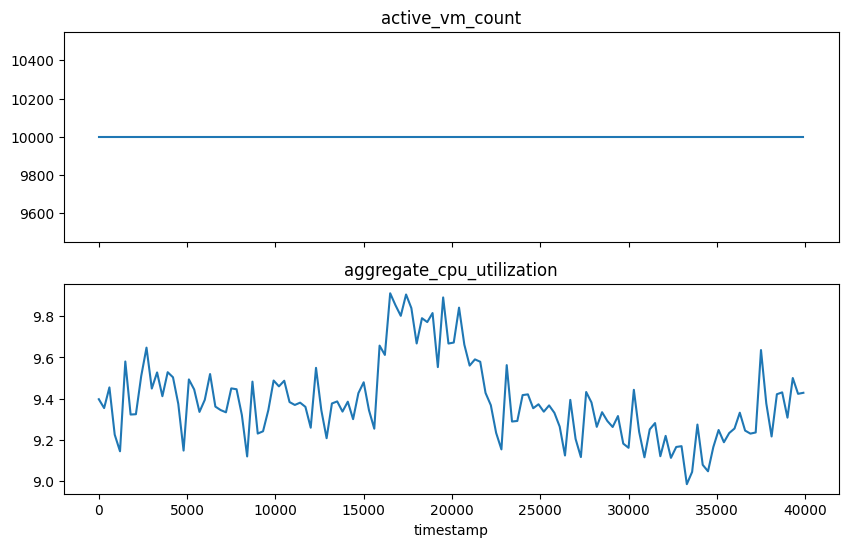

In [17]:
fig, ax = plt.subplots(2, 1, sharex=True, figsize=(10, 6))
active.plot(ax=ax[0], title="active_vm_count")
agg_cpu.plot(ax=ax[1], title="aggregate_cpu_utilization")
plt.show()

In [18]:
print(active.min(), active.max(), df.groupby("vm_id").size().nunique())

10000 10000 1


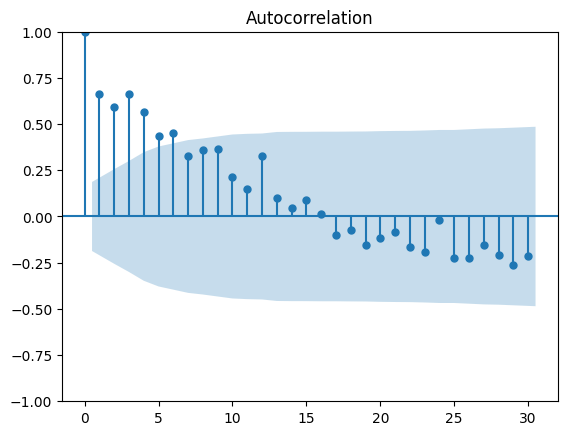

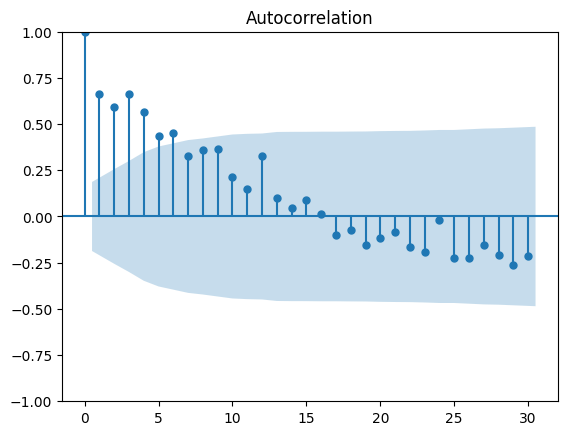

In [19]:
plot_acf(agg_cpu.iloc[:110], lags=30)

###### ACF of the first 110 points. Reading: lag 1 is about 0.66 and decays slowly. It is inside the confidence band beyond roughly lag 6, and the small lag-12 bump is not significant.

In [20]:
meta = pd.read_csv("../challenge_data/vm_metadata.csv.gz")
print(meta.columns.tolist())

['vm_id', 'subscription_id', 'deployment_id', 'timestamp_vm_created', 'timestamp_vm_deleted', 'max_cpu', 'avg_cpu', 'p95_max_cpu', 'vm_category', 'virtual_core_bucket', 'memory_gb_bucket']


In [21]:
meta.head()

,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4
3,88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...,4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...,yfPM2qpoqC9aXMgM7S0mCLxCY8NEd4C6uiLpfY443SV5Yj...,0,70200,98.738842,81.578650,98.439173,Unknown,4,8
4,C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...,1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...,hrP166UPejKeASJ3ibhQ68YrE7iDxsmlXNZ2B8BBy0BMKn...,0,2591400,90.790129,2.382323,6.902215,Delay-insensitive,2,4


In [22]:
obs_mean = df.groupby("vm_id")["avg_cpu"].mean().rename("window_avg")
chk = meta.set_index("vm_id").join(obs_mean)
print(chk[["avg_cpu", "window_avg"]].corr())

             avg_cpu  window_avg
avg_cpu     1.000000    0.871228
window_avg  0.871228    1.000000


###### compare metadata avg_cpu with each VM's mean CPU inside the window. correlation 0.87. The lifetime columns carry information about the window and the holdout, so they must not be used as model features.

In [23]:
print(meta["timestamp_vm_created"].describe())
print(meta["timestamp_vm_deleted"].describe())
print((meta["timestamp_vm_created"] <= 0).mean(),
      (meta["timestamp_vm_deleted"] >= df["timestamp"].max()).mean())

count    10000.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0
Name: timestamp_vm_created, dtype: float64
count    1.000000e+04
mean     2.289626e+06
std      7.081008e+05
min      4.050000e+04
25%      2.591400e+06
50%      2.591400e+06
75%      2.591400e+06
max      2.591400e+06
Name: timestamp_vm_deleted, dtype: float64
1.0 1.0


vm_category
Delay-insensitive    6180
Interactive          3091
Unknown               729
Name: vm_id, dtype: int64
virtual_core_bucket
2      7534
24       62
4      1908
8       486
>24      10
Name: vm_id, dtype: int64
memory_gb_bucket
2      3904
32     1383
4      2475
64       82
8      2146
>64      10
Name: vm_id, dtype: int64


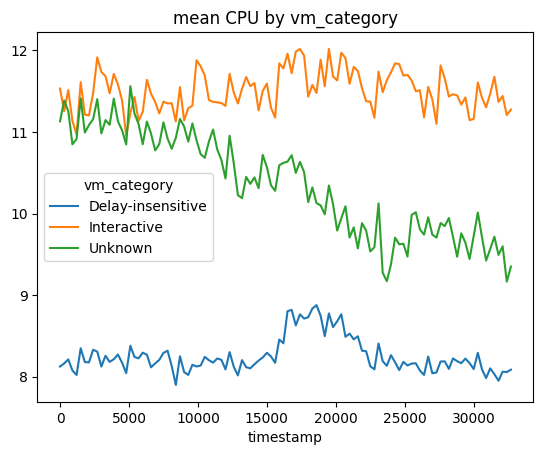

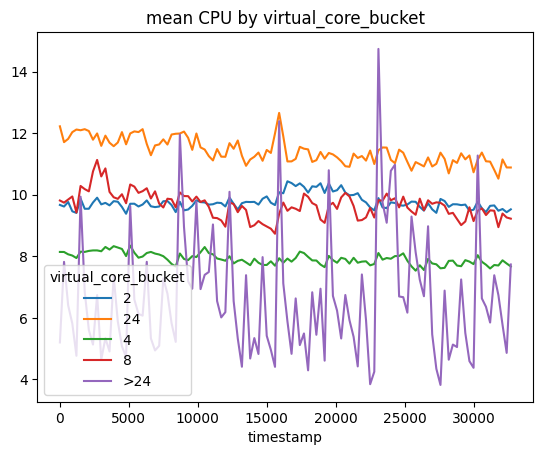

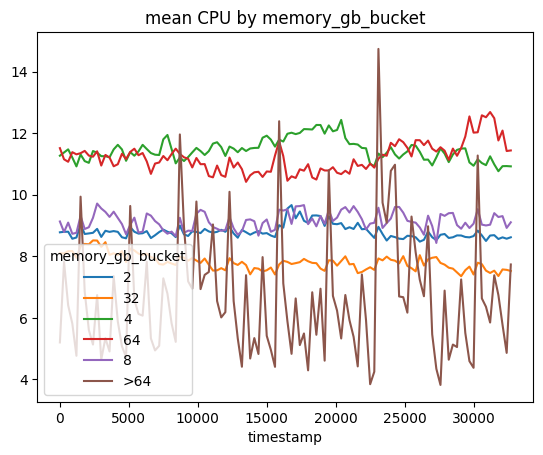

In [24]:
seg = df.merge(meta[["vm_id", "vm_category", "virtual_core_bucket", "memory_gb_bucket"]], on="vm_id")

for col in ["vm_category", "virtual_core_bucket", "memory_gb_bucket"]:
    print(seg.groupby(col)["vm_id"].nunique())
    ts = seg.groupby([col, "timestamp"])["avg_cpu"].mean().unstack(0)
    ts.iloc[:110].plot(title=f"mean CPU by {col}")

In [25]:
for col in ["vm_category", "virtual_core_bucket", "memory_gb_bucket"]:
    print(meta[col].value_counts(), "\n")

vm_category
Delay-insensitive    6180
Interactive          3091
Unknown               729
Name: count, dtype: int64 

virtual_core_bucket
2      7534
4      1908
8       486
24       62
>24      10
Name: count, dtype: int64 

memory_gb_bucket
2      3904
4      2475
8      2146
32     1383
64       82
>64      10
Name: count, dtype: int64 



<Axes: title={'center': 'contribution to aggregate CPU'}, xlabel='timestamp'>

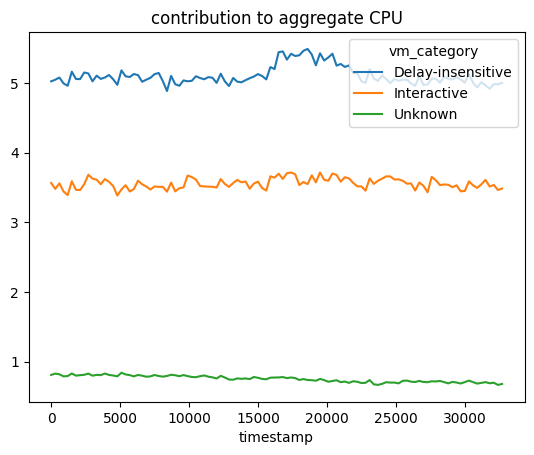

In [26]:
seg = df.merge(meta[["vm_id", "vm_category"]], on="vm_id")
share = meta["vm_category"].value_counts(normalize=True)
means = seg.groupby(["timestamp", "vm_category"])["avg_cpu"].mean().unstack()
contrib = means * share
contrib.iloc[:110].plot(title="contribution to aggregate CPU")

###### Contribution to the aggregate = segment share x segment mean. Because the cohort is closed, shares are constant, so this is an exact decomposition. Delay-insensitive contributes the most and drives the bump around 15,000-20,000 s. Unknown looks dramatic but is only about 7% of VMs.

(-1.7348231782504901, 0.4132656887034489, 12, 97, {'1%': np.float64(-3.4996365338407074), '5%': np.float64(-2.8918307730370025), '10%': np.float64(-2.5829283377617176)}, np.float64(-153.38915932082136))


<Axes: title={'center': 'Autocorrelation'}, xlabel='timestamp'>

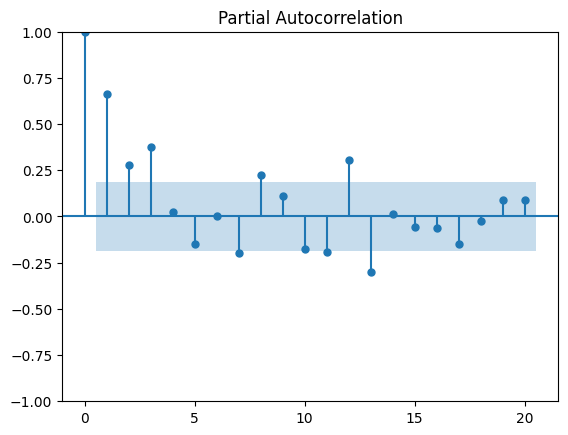

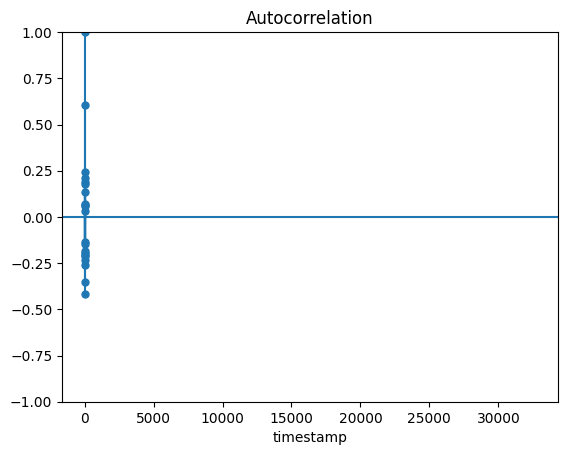

In [27]:
train = agg_cpu.iloc[:110]
plot_pacf(train, lags=20)                    
print(adfuller(train))                       
plot_acf(train.diff().dropna(), lags=20)     
train.plot(); train.rolling(12).mean().plot()

In [28]:
from statsmodels.tsa.stattools import adfuller, kpss

# trend-stationary alternative
print(adfuller(train, regression="ct", autolag="AIC"))
# fewer lags, less power loss
print(adfuller(train, maxlag=3, autolag=None))
# KPSS has the opposite null (null = stationary)
print(kpss(train, regression="c", nlags="auto"))

(-1.805573147361851, 0.7020648180208336, 12, 97, {'1%': np.float64(-4.055269281670434), '5%': np.float64(-3.456761928280994), '10%': np.float64(-3.154147345270431)}, np.float64(-151.85992856275743))
(-1.493684096315826, 0.5366333803029122, 3, 106, {'1%': np.float64(-3.4936021509366793), '5%': np.float64(-2.8892174239808703), '10%': np.float64(-2.58153320754717)})
(np.float64(0.30747957609128357), np.float64(0.1), 5, {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739})


In [29]:
from statsforecast import StatsForecast
from statsforecast.models import Naive, SeasonalNaive, HistoricAverage, WindowAverage

###### statsforecast needs a long table with columns `unique_id`, `ds`, `y`. The table reshapes the training series. The index is replaced by integer steps 0..109.

In [30]:
train = agg_cpu.iloc[:110].reset_index(drop=True)
sf_df = pd.DataFrame({"unique_id": "agg_cpu", "ds": np.arange(len(train)), "y": train.values})

In [31]:
sf_df.head()

,unique_id,ds,y
0,agg_cpu,0,9.396898
1,agg_cpu,1,9.353775
2,agg_cpu,2,9.454383
3,agg_cpu,3,9.224419
4,agg_cpu,4,9.143503


In [57]:
sf = StatsForecast(
    models=[Naive(), WindowAverage(window_size=24), SeasonalNaive(season_length=12), HistoricAverage()],
    freq=1
)

In [58]:
H = 24
cv = sf.cross_validation(df=sf_df, h=H, step_size=4, n_windows=10)

In [59]:
print(cv.groupby("cutoff").size())
print(cv["cutoff"].min(), cv["ds"].max())

cutoff
49    24
53    24
57    24
61    24
65    24
69    24
73    24
77    24
81    24
85    24
dtype: int64
49 109


In [60]:
models = ["Naive", "WindowAverage", "SeasonalNaive", "HistoricAverage"]
rows = []
for m in models:
    e = cv["y"] - cv[m]
    rows.append({"model": m, "MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean())})
res = pd.DataFrame(rows).set_index("model")
res["RMSE_vs_Naive"] = res["RMSE"] / res.loc["Naive", "RMSE"]
print(res.round(4))

                    MAE    RMSE  RMSE_vs_Naive
model                                         
Naive            0.2392  0.2920         1.0000
WindowAverage    0.2768  0.3077         1.0540
SeasonalNaive    0.2750  0.3238         1.1089
HistoricAverage  0.2037  0.2400         0.8221


###### Per-fold view: HistoricAverage wins 5 of 10 folds and Naive wins 5. The pooled gap is driven by folds 61-69 (cutoffs near the end of the delay-insensitive bump), where Naive carries a temporarily high level forward.

In [36]:
cv["step"] = cv.groupby("cutoff").cumcount() + 1
fold = cv.assign(**{m: (cv["y"] - cv[m])**2 for m in ["Naive", "HistoricAverage"]}) \
    .groupby("cutoff")[["Naive", "HistoricAverage"]].mean() ** 0.5
print(fold.round(3)); print((fold["HistoricAverage"] < fold["Naive"]).sum(), "of", len(fold))

        Naive  HistoricAverage
cutoff                        
49      0.303            0.337
53      0.202            0.335
57      0.307            0.271
61      0.346            0.210
65      0.496            0.178
69      0.333            0.177
73      0.152            0.193
77      0.273            0.190
81      0.167            0.205
85      0.154            0.233
5 of 10


In [37]:
cv2 = cv.assign(**{m: (cv["y"] - cv[m]).abs() for m in models})
print(cv2.groupby("step")[models].mean().round(3))

      Naive  WindowAverage  SeasonalNaive  HistoricAverage
step                                                      
1     0.098          0.231          0.266            0.197
2     0.131          0.264          0.335            0.241
3     0.162          0.255          0.235            0.229
4     0.131          0.241          0.243            0.206
5     0.182          0.279          0.264            0.223
6     0.227          0.333          0.351            0.281
7     0.216          0.281          0.236            0.229
8     0.154          0.253          0.236            0.195
9     0.249          0.303          0.247            0.228
10    0.262          0.324          0.284            0.249
11    0.220          0.282          0.193            0.207
12    0.205          0.250          0.205            0.180
13    0.260          0.285          0.318            0.194
14    0.295          0.326          0.374            0.235
15    0.274          0.303          0.305            0.2

###### Summary and next steps
Panel is complete and regular; active_vm_count is constant  10,000 (closed cohort, selection effect).
Aggregate CPU is persistent at short lags (PACF significant to lag 3) with no usable seasonality; stationarity tests are inconclusive.
- Delay-insensitive VMs drive most of the aggregates movement; tiny segments are noise.
- No baseline is uniformly best: Naive wins short horizons, HistoricAverage wins long ones and 5 of 10 folds.

Next steps
1. Add one or two mean-reverting models to the same CV (AR(3) / damped ETS) and compare per fold and per horizon.
2. Choose the final model from CV only; refit on all 110 points; forecast the 24 holdout steps once.
3. Map forecast steps 110-133 to the real timestamps and write `predictions.csv` in the SUBMISSION.md schema.
4. Score the holdout once, report MAE, RMSE and relative improvement, plus peak-period error.
5. Build an uncertainty band from CV residuals and turn it into a headroom rule.
6. Move this code into `src/`, add leakage tests, and write the README and report.

In [ ]:
# running the same CV on the count series
cnt = active.iloc[:110].reset_index(drop=True)
cnt_df = pd.DataFrame({"unique_id": "active", "ds": np.arange(110), "y": cnt.values})
cv_cnt = StatsForecast(models=[Naive()], freq="").cross_validation(
    df=cnt_df, h=24, step_size=4, n_windows=10)
e = cv_cnt["y"] - cv_cnt["Naive"]
print(e.abs().mean(), (e**2).mean() ** 0.5) 

0.0 0.0


In [50]:
# rows per timestamp: should be 10,000 at every step
print(df.groupby("timestamp").size().unique())

# do the readings and the metadata describe the same VMs?
print(set(df["vm_id"]) == set(meta["vm_id"]), meta["vm_id"].is_unique)

# does any VM start late or stop early?
print(df.groupby("vm_id")["timestamp"].agg(["min", "max"]).drop_duplicates())

[10000]
True True
                                                    min    max
vm_id                                                         
++HH65MmT9ktdMdfSKCLk9O/VFunMJLxKrbFC64hN4zKe5V...    0  39900
